In [1]:

import torch
import torchvision
import platform

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("GPU Status: AVAILABLE")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU Status: NOT AVAILABLE — CPU mode")


Python version: 3.13.15
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU Status: AVAILABLE
GPU Name: Tesla T4


In [1]:

from pathlib import Path
import json

# Main project directory
PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")

# Professional project folders
folders = [
    "data",
    "data/raw",
    "data/processed",
    "configs",
    "src",
    "models",
    "outputs",
    "outputs/figures",
    "outputs/metrics",
    "outputs/predictions",
    "reports",
    "tests",
    "logs"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Reproducible project configuration
config = {
    "project_name": "Enterprise-Grade Deep Residual Image Classification Pipeline",
    "framework": "PyTorch",
    "dataset": "CIFAR-10",
    "num_classes": 10,
    "image_size": 32,
    "input_channels": 3,
    "batch_size": 64,
    "epochs": 15,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "random_seed": 42,
    "dropout": 0.3,
    "gradient_clip_norm": 1.0,
    "device": "cuda" if __import__("torch").cuda.is_available() else "cpu"
}

config_path = PROJECT_DIR / "configs" / "config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("PROJECT STRUCTURE CREATED SUCCESSFULLY")
print("-" * 55)
print("Project location:", PROJECT_DIR)
print("Configuration saved:", config_path)
print("Device:", config["device"])
print("\nCreated folders:")

for folder in folders:
    print("  [OK]", folder)


PROJECT STRUCTURE CREATED SUCCESSFULLY
-------------------------------------------------------
Project location: /content/Deep-Residual-Image-Classification
Configuration saved: /content/Deep-Residual-Image-Classification/configs/config.json
Device: cuda

Created folders:
  [OK] data
  [OK] data/raw
  [OK] data/processed
  [OK] configs
  [OK] src
  [OK] models
  [OK] outputs
  [OK] outputs/figures
  [OK] outputs/metrics
  [OK] outputs/predictions
  [OK] reports
  [OK] tests
  [OK] logs


In [2]:

import torch
from torchvision import datasets
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
DATA_DIR = PROJECT_DIR / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download official CIFAR-10 training and test datasets
print("Downloading/loading CIFAR-10 dataset...")

train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True
)

# Verify dataset
class_names = train_dataset.classes

print("\n" + "=" * 55)
print("CIFAR-10 DATASET VERIFICATION")
print("=" * 55)

print("Training images:", len(train_dataset))
print("Official test images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Image dimensions:", train_dataset[0][0].size)
print("Image mode:", train_dataset[0][0].mode)

print("\nClass names:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

train_counts = Counter(train_dataset.targets)
test_counts = Counter(test_dataset.targets)

print("\nTraining images per class:")
for i, name in enumerate(class_names):
    print(f"{name}: {train_counts[i]}")

print("\nTest images per class:")
for i, name in enumerate(class_names):
    print(f"{name}: {test_counts[i]}")

assert len(train_dataset) == 50000
assert len(test_dataset) == 10000
assert len(class_names) == 10

print("\nSUCCESS: Dataset downloaded and verified!")


Downloading/loading CIFAR-10 dataset...


100%|██████████| 170M/170M [25:47<00:00, 110kB/s]



CIFAR-10 DATASET VERIFICATION
Training images: 50000
Official test images: 10000
Number of classes: 10
Image dimensions: (32, 32)
Image mode: RGB

Class names:
0: airplane
1: automobile
2: bird
3: cat
4: deer
5: dog
6: frog
7: horse
8: ship
9: truck

Training images per class:
airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000

Test images per class:
airplane: 1000
automobile: 1000
bird: 1000
cat: 1000
deer: 1000
dog: 1000
frog: 1000
horse: 1000
ship: 1000
truck: 1000

SUCCESS: Dataset downloaded and verified!


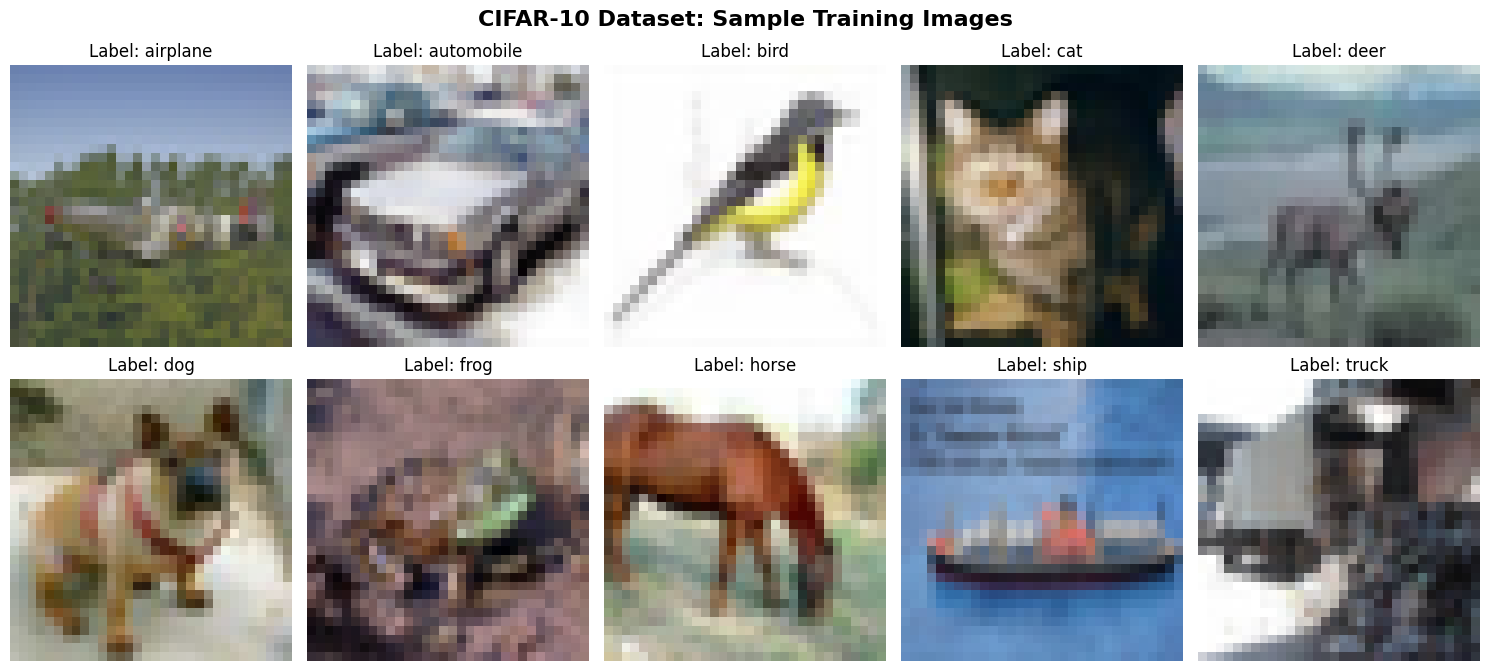

Visual inspection completed.
All 10 CIFAR-10 classes are represented above.


In [3]:

import matplotlib.pyplot as plt
import random

# Reproducible sample selection
random.seed(42)

class_names = train_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
fig.suptitle(
    "CIFAR-10 Dataset: Sample Training Images",
    fontsize=16,
    fontweight="bold"
)

for class_id, ax in enumerate(axes.flat):
    # Find one image belonging to this class
    candidates = [
        i for i, label in enumerate(train_dataset.targets)
        if label == class_id
    ]
    image_index = random.choice(candidates)

    image, label = train_dataset[image_index]

    ax.imshow(image)
    ax.set_title(f"Label: {class_names[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Visual inspection completed.")
print("All 10 CIFAR-10 classes are represented above.")


In [4]:

import random
import numpy as np
import torch
from torch.utils.data import random_split

# 1. Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behaviour where supported
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 2. Split original training dataset: 90% train, 10% validation
train_size = 45000
val_size = 5000

split_generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=split_generator
)

# 3. Verify the split
print("=" * 55)
print("REPRODUCIBLE DATASET SPLIT")
print("=" * 55)

print("Random seed:", SEED)
print("Training subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Official test dataset:", len(test_dataset))
print("Total images:", len(train_subset) + len(val_subset) + len(test_dataset))

# 4. Confirm that train and validation indices do not overlap
train_indices = set(train_subset.indices)
val_indices = set(val_subset.indices)

assert len(train_indices & val_indices) == 0
assert len(train_subset) == 45000
assert len(val_subset) == 5000
assert len(test_dataset) == 10000

print("\nSUCCESS: Split sizes verified.")
print("SUCCESS: Training and validation indices do not overlap.")
print("Official test dataset remains separate.")


REPRODUCIBLE DATASET SPLIT
Random seed: 42
Training subset: 45000
Validation subset: 5000
Official test dataset: 10000
Total images: 60000

SUCCESS: Split sizes verified.
SUCCESS: Training and validation indices do not overlap.
Official test dataset remains separate.


In [5]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import Subset

PROJECT_DIR = "/content/Deep-Residual-Image-Classification"
DATA_DIR = f"{PROJECT_DIR}/data/raw"

# CIFAR-10 normalization values from your report
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2023, 0.1994, 0.2010)

# Training augmentation
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Validation/test: no random augmentation
evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Create separate dataset objects so each split uses
# the correct transformations.
train_augmented_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=train_transform
)

train_evaluation_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=evaluation_transform
)

test_evaluation_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=evaluation_transform
)

# Reuse the exact split indices created in Step 7
train_dataset_final = Subset(
    train_augmented_dataset,
    train_subset.indices
)

val_dataset_final = Subset(
    train_evaluation_dataset,
    val_subset.indices
)

test_dataset_final = test_evaluation_dataset

# Verify a sample from each dataset
train_image, train_label = train_dataset_final[0]
val_image, val_label = val_dataset_final[0]
test_image, test_label = test_dataset_final[0]

print("=" * 55)
print("PREPROCESSING VERIFICATION")
print("=" * 55)

print("Training images:", len(train_dataset_final))
print("Validation images:", len(val_dataset_final))
print("Test images:", len(test_dataset_final))

print("\nTraining tensor shape:", tuple(train_image.shape))
print("Validation tensor shape:", tuple(val_image.shape))
print("Test tensor shape:", tuple(test_image.shape))

print("\nTraining label:", train_label)
print("Validation label:", val_label)
print("Test label:", test_label)

assert train_image.shape == (3, 32, 32)
assert val_image.shape == (3, 32, 32)
assert test_image.shape == (3, 32, 32)

print("\nSUCCESS: All transformations are configured correctly.")


PREPROCESSING VERIFICATION
Training images: 45000
Validation images: 5000
Test images: 10000

Training tensor shape: (3, 32, 32)
Validation tensor shape: (3, 32, 32)
Test tensor shape: (3, 32, 32)

Training label: 6
Validation label: 7
Test label: 3

SUCCESS: All transformations are configured correctly.


In [6]:

import torch
from torch.utils.data import DataLoader

# Project configuration
BATCH_SIZE = 64
SEED = 42

# Reproducible shuffle for training
loader_generator = torch.Generator().manual_seed(SEED)

# Colab-safe worker configuration
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    val_dataset_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    test_dataset_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0)
)

# Verify that batches load correctly
images, labels = next(iter(train_loader))

print("=" * 55)
print("DATALOADER VERIFICATION")
print("=" * 55)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Sample image batch shape:", tuple(images.shape))
print("Sample label batch shape:", tuple(labels.shape))
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)
print("GPU pin_memory:", PIN_MEMORY)

assert images.shape[0] <= BATCH_SIZE
assert images.shape[1:] == (3, 32, 32)
assert labels.ndim == 1
assert len(train_loader) == 704
assert len(val_loader) == 79
assert len(test_loader) == 157

print("\nSUCCESS: DataLoaders are working correctly.")


DATALOADER VERIFICATION
Batch size: 64
Training batches: 704
Validation batches: 79
Test batches: 157
Sample image batch shape: (64, 3, 32, 32)
Sample label batch shape: (64,)
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
GPU pin_memory: True

SUCCESS: DataLoaders are working correctly.


In [7]:

import torch
import torch.nn as nn
import json
from pathlib import Path

# Main project directory
PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")

class ResidualBlock(nn.Module):
    """Two convolution layers with an identity shortcut."""

    def __init__(self, channels=64):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, channels, kernel_size=3,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(channels)

        self.conv2 = nn.Conv2d(
            channels, channels, kernel_size=3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(channels)

        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Identity shortcut
        out = out + identity
        out = self.relu(out)

        # Downsample spatial dimensions
        out = self.pool(out)

        return out


class DeepResidualCNN(nn.Module):
    """CIFAR-10 residual CNN based on the project report."""

    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 64, kernel_size=3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.residual_block1 = ResidualBlock(64)
        self.residual_block2 = ResidualBlock(64)

        self.dropout = nn.Dropout2d(p=0.3)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.residual_block1(x)
        x = self.residual_block2(x)
        x = self.dropout(x)
        x = self.classifier(x)
        return x


# Initialize model on available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DeepResidualCNN(num_classes=10).to(device)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Test one batch with a forward pass
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

model.eval()
with torch.no_grad():
    sample_outputs = model(sample_images)

print("=" * 55)
print("DEEP RESIDUAL CNN MODEL VERIFICATION")
print("=" * 55)
print("Device:", device)
print("Architecture:", model.__class__.__name__)
print("Trainable parameters:", f"{total_parameters:,}")
print("Input batch shape:", tuple(sample_images.shape))
print("Output logits shape:", tuple(sample_outputs.shape))
print("Expected classes:", 10)

assert sample_outputs.shape == (sample_images.shape[0], 10)
assert torch.isfinite(sample_outputs).all()

# Save architecture summary to project reports
summary = {
    "architecture": "DeepResidualCNN",
    "input_shape": [3, 32, 32],
    "num_classes": 10,
    "trainable_parameters": total_parameters,
    "device_used_for_test": str(device)
}

summary_path = PROJECT_DIR / "reports" / "model_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("\nModel summary saved:", summary_path)
print("SUCCESS: Forward pass completed.")


DEEP RESIDUAL CNN MODEL VERIFICATION
Device: cuda
Architecture: DeepResidualCNN
Trainable parameters: 1,201,226
Input batch shape: (64, 3, 32, 32)
Output logits shape: (64, 10)
Expected classes: 10

Model summary saved: /content/Deep-Residual-Image-Classification/reports/model_summary.json
SUCCESS: Forward pass completed.


In [8]:

import torch
import torch.nn as nn
import json
from pathlib import Path

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")

# 1. Loss function
criterion = nn.CrossEntropyLoss()

# 2. AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# 3. Learning-rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# 4. Gradient clipping configuration
MAX_GRAD_NORM = 1.0

# 5. Mixed precision support
USE_AMP = torch.cuda.is_available()

# Modern PyTorch AMP setup
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# 6. Save training configuration
training_config = {
    "epochs": 15,
    "batch_size": 64,
    "optimizer": "AdamW",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "loss_function": "CrossEntropyLoss",
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "min",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "gradient_clip_norm": MAX_GRAD_NORM,
    "mixed_precision_enabled": USE_AMP,
    "random_seed": 42
}

config_path = PROJECT_DIR / "configs" / "training_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(training_config, f, indent=4)

# 7. Verify configuration
print("=" * 55)
print("TRAINING CONFIGURATION VERIFICATION")
print("=" * 55)

print("Device:", device)
print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print("Scheduler:", scheduler.__class__.__name__)
print("Scheduler factor:", scheduler.factor)
print("Scheduler patience:", scheduler.patience)
print("Gradient clipping norm:", MAX_GRAD_NORM)
print("Mixed precision enabled:", USE_AMP)
print("Epochs:", training_config["epochs"])

assert optimizer.param_groups[0]["lr"] == 0.001
assert optimizer.param_groups[0]["weight_decay"] == 0.0001
assert MAX_GRAD_NORM == 1.0

print("\nConfiguration saved:", config_path)
print("SUCCESS: Training components are ready.")


TRAINING CONFIGURATION VERIFICATION
Device: cuda
Loss function: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau
Scheduler factor: 0.5
Scheduler patience: 2
Gradient clipping norm: 1.0
Mixed precision enabled: True
Epochs: 15

Configuration saved: /content/Deep-Residual-Image-Classification/configs/training_config.json
SUCCESS: Training components are ready.


In [9]:

import csv
import json
import time
from pathlib import Path

import torch
import torch.nn as nn
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
MODELS_DIR = PROJECT_DIR / "models"
LOGS_DIR = PROJECT_DIR / "logs"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 15
MAX_GRAD_NORM = 1.0
USE_AMP = torch.cuda.is_available()

# Use the previously configured model, optimizer, scheduler,
# criterion and scaler from Step 11.
history = []
best_val_loss = float("inf")
best_epoch = 0
start_time = time.time()

metrics_path = METRICS_DIR / "training_history.csv"
checkpoint_path = MODELS_DIR / "best_model.pth"
last_checkpoint_path = MODELS_DIR / "last_checkpoint.pth"

def run_validation():
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples

try:
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_start = time.time()

        running_loss = 0.0
        running_correct = 0
        total_samples = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch}/{EPOCHS}",
            leave=True
        )

        for images, labels in progress:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()

            # Unscale gradients before clipping
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=MAX_GRAD_NORM
            )

            scaler.step(optimizer)
            scaler.update()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            running_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total_samples += batch_size

            progress.set_postfix(
                loss=f"{running_loss / total_samples:.4f}",
                accuracy=f"{running_correct / total_samples:.3f}"
            )

        train_loss = running_loss / total_samples
        train_accuracy = running_correct / total_samples

        val_loss, val_accuracy = run_validation()

        # Reduce learning rate when validation loss plateaus
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        epoch_seconds = time.time() - epoch_start

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "learning_rate": current_lr,
            "epoch_seconds": epoch_seconds
        }
        history.append(record)

        # Save history after every epoch
        with open(metrics_path, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=record.keys())
            writer.writeheader()
            writer.writerows(history)

        # Save the best checkpoint using validation loss only
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "best_val_loss": best_val_loss,
                    "val_accuracy": val_accuracy,
                    "class_names": train_dataset.classes,
                    "config": training_config
                },
                checkpoint_path
            )

        # Save a recovery checkpoint after every epoch
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "history": history,
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch
            },
            last_checkpoint_path
        )

        print(
            f"\nEpoch {epoch}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_accuracy:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.4f} | "
            f"LR: {current_lr:.6f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

except KeyboardInterrupt:
    print("\nTraining interrupted by user. Completed epochs have been saved.")

total_minutes = (time.time() - start_time) / 60

# Save a summary of the training run
training_summary = {
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_validation_loss": (
        best_val_loss if best_epoch > 0 else None
    ),
    "training_minutes": round(total_minutes, 2),
    "best_checkpoint": str(checkpoint_path),
    "metrics_csv": str(metrics_path)
}

summary_path = LOGS_DIR / "training_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(training_summary, f, indent=4)

print("\n" + "=" * 60)
print("TRAINING RUN SUMMARY")
print("=" * 60)
print(json.dumps(training_summary, indent=2))
print("\nTraining history:", metrics_path)
print("Best model checkpoint:", checkpoint_path)
print("Latest recovery checkpoint:", last_checkpoint_path)


Epoch 1/15:   0%|          | 0/704 [00:00<?, ?it/s]


Epoch 1/15 | Train loss: 1.7845 | Train accuracy: 0.3414 | Val loss: 1.3668 | Val accuracy: 0.4982 | LR: 0.001000 | Time: 31.7s


Epoch 2/15:   0%|          | 0/704 [00:00<?, ?it/s]


Epoch 2/15 | Train loss: 1.4873 | Train accuracy: 0.4488 | Val loss: 1.1737 | Val accuracy: 0.5906 | LR: 0.001000 | Time: 31.5s


Epoch 3/15:   0%|          | 0/704 [00:00<?, ?it/s]

...


Epoch 13/15 | Train loss: 0.8774 | Train accuracy: 0.6940 | Val loss: 0.6529 | Val accuracy: 0.7672 | LR: 0.001000 | Time: 31.4s


Epoch 14/15:   0%|          | 0/704 [00:00<?, ?it/s]


Epoch 14/15 | Train loss: 0.8526 | Train accuracy: 0.7026 | Val loss: 0.6720 | Val accuracy: 0.7658 | LR: 0.001000 | Time: 32.0s


Epoch 15/15:   0%|          | 0/704 [00:00<?, ?it/s]


Epoch 15/15 | Train loss: 0.8327 | Train accuracy: 0.7093 | Val loss: 0.6271 | Val accuracy: 0.7780 | LR: 0.001000 | Time: 32.1s

TRAINING RUN SUMMARY
{
  "epochs_completed": 15,
  "best_epoch": 15,
  "best_validation_loss": 0.6271113224029541,
  "training_minutes": 8.03,
  "best_checkpoint": "/content/Deep-Residual-Image-Classification/models/best_model.pth",
  "metrics_csv": "/content/Deep-Residual-Image-Classification/outputs/metrics/training_history.csv"
}

Training history: /content/Deep-Residual-Image-Classification/outputs/metrics/training_history.csv
Best model checkpoint: /content/Deep-Residual-Image-Classification/models/best_model.pth
Latest recovery checkpoint: /content/Deep-Residual-Image-Classification/models/last_checkpoint.pth


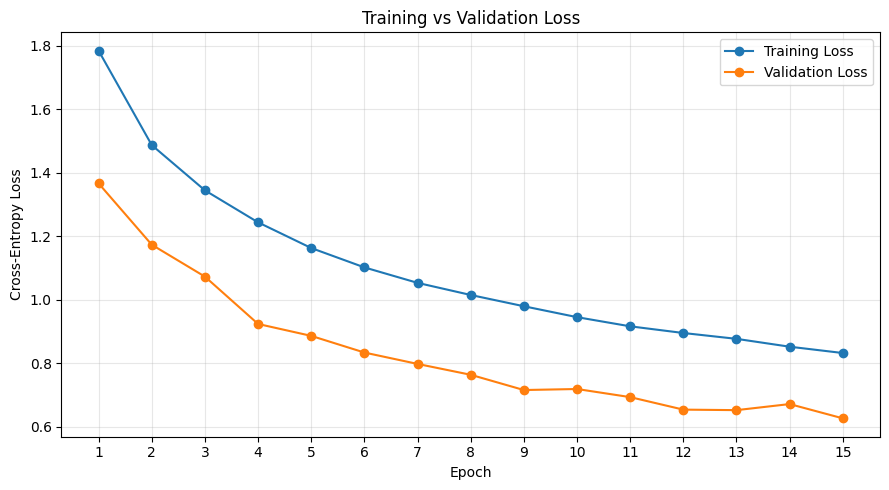

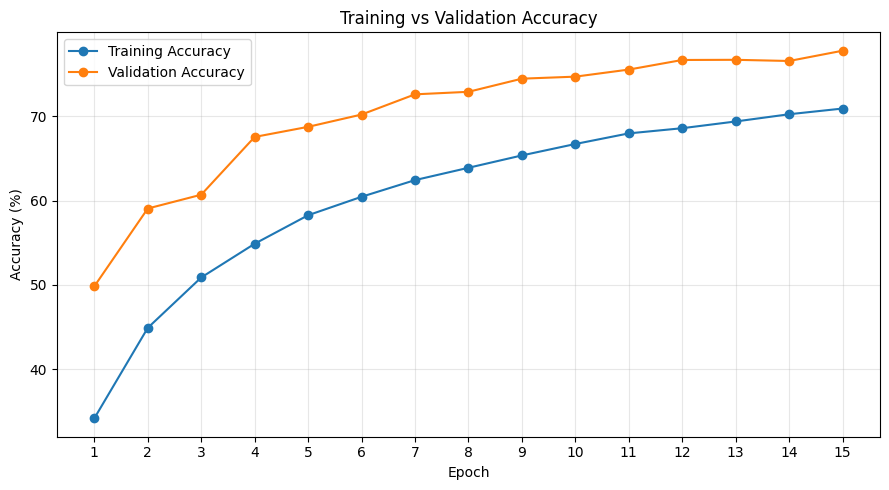

TRAINING VISUALIZATION COMPLETE
Epochs plotted: 15
Loss graph: /content/Deep-Residual-Image-Classification/outputs/figures/training_validation_loss.png
Accuracy graph: /content/Deep-Residual-Image-Classification/outputs/figures/training_validation_accuracy.png

Last recorded epoch:
 epoch  train_loss  train_accuracy  val_loss  val_accuracy  learning_rate  epoch_seconds
    15    0.832746        0.709333  0.627111         0.778          0.001      32.060096

SUCCESS: Both graphs saved at 300 DPI.


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

history_path = METRICS_DIR / "training_history.csv"
history_df = pd.read_csv(history_path)

assert len(history_df) > 0, "Training history is empty."

# 1. Training and validation loss
plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_loss"],
         marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.xticks(history_df["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

loss_path = FIGURES_DIR / "training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. Training and validation accuracy
plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"] * 100,
         marker="o", label="Training Accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"] * 100,
         marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.xticks(history_df["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

accuracy_path = FIGURES_DIR / "training_validation_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("=" * 55)
print("TRAINING VISUALIZATION COMPLETE")
print("=" * 55)
print("Epochs plotted:", len(history_df))
print("Loss graph:", loss_path)
print("Accuracy graph:", accuracy_path)
print("\nLast recorded epoch:")
print(history_df.tail(1).to_string(index=False))
print("\nSUCCESS: Both graphs saved at 300 DPI.")


Loaded best checkpoint from epoch: 15
Best validation loss: 0.6271113224029541

OFFICIAL CIFAR-10 TEST RESULTS
test_samples: 10000
accuracy: 0.7790 (77.90%)
macro_precision: 0.7793 (77.93%)
macro_recall: 0.7790 (77.90%)
macro_f1: 0.7771 (77.71%)
macro_roc_auc_ovr: 0.9747 (97.47%)
macro_average_precision: 0.8615 (86.15%)
selected_checkpoint_epoch: 15
validation_loss_at_checkpoint: 0.6271 (62.71%)

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane       0.79      0.80      0.80      1000
  automobile       0.95      0.86      0.90      1000
        bird       0.70      0.65      0.67      1000
         cat       0.64      0.50      0.56      1000
        deer       0.70      0.82      0.76      1000
         dog       0.66      0.73      0.69      1000
        frog       0.80      0.84      0.82      1000
       horse       0.80      0.83      0.81      1000
        ship       0.91      0.86      0.88      1000
       truck       0.85    

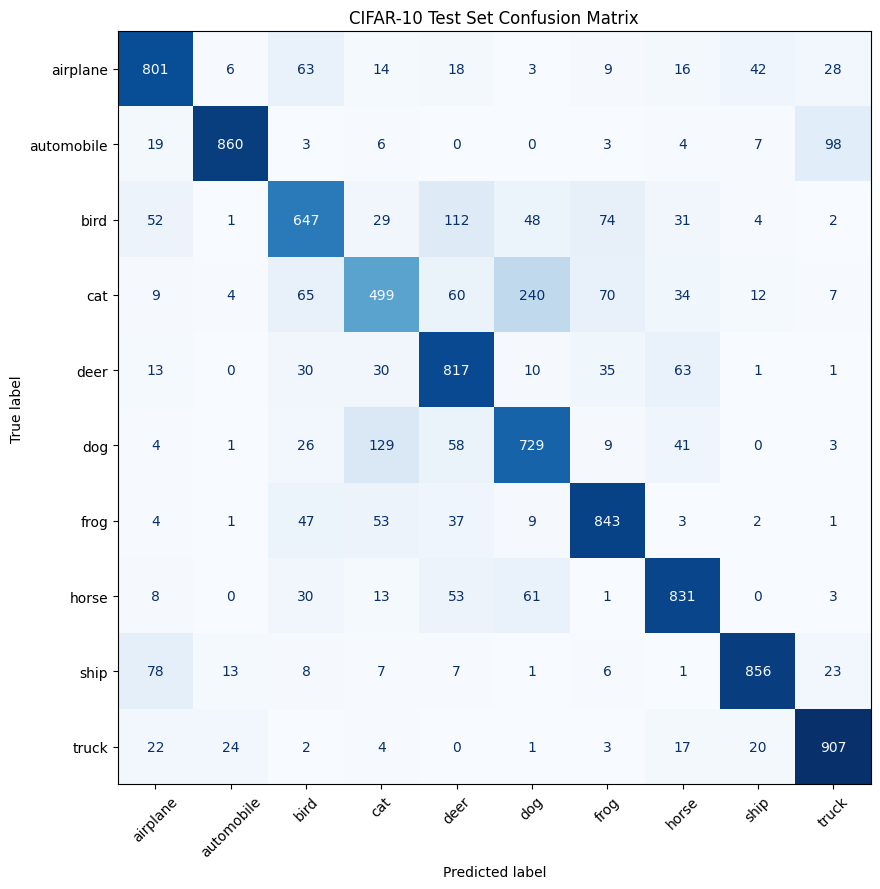


Saved test metrics: /content/Deep-Residual-Image-Classification/outputs/metrics/test_metrics.json
Saved classification report: /content/Deep-Residual-Image-Classification/outputs/metrics/classification_report.csv
Saved predictions: /content/Deep-Residual-Image-Classification/outputs/predictions/test_predictions.csv
Saved confusion matrix: /content/Deep-Residual-Image-Classification/outputs/figures/test_confusion_matrix.png

SUCCESS: Official test evaluation completed.


In [11]:

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
MODELS_DIR = PROJECT_DIR / "models"
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
REPORTS_DIR = PROJECT_DIR / "reports"

for folder in [METRICS_DIR, FIGURES_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. Load best checkpoint selected by validation loss
checkpoint_path = MODELS_DIR / "best_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# 2. Evaluate on the untouched official test dataset
all_labels = []
all_predictions = []
all_probabilities = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            logits = model(images)

        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.append(probabilities.cpu().numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.concatenate(all_probabilities, axis=0)

class_names = test_dataset.classes

# 3. Calculate metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_roc_auc = roc_auc_score(
    y_true, y_prob, multi_class="ovr", average="macro"
)

# Multiclass average precision: one-vs-rest per class, then macro average
y_true_onehot = np.eye(len(class_names))[y_true]
test_average_precision = average_precision_score(
    y_true_onehot, y_prob, average="macro"
)

metrics = {
    "test_samples": int(len(y_true)),
    "accuracy": float(test_accuracy),
    "macro_precision": float(test_precision),
    "macro_recall": float(test_recall),
    "macro_f1": float(test_f1),
    "macro_roc_auc_ovr": float(test_roc_auc),
    "macro_average_precision": float(test_average_precision),
    "selected_checkpoint_epoch": int(checkpoint["epoch"]),
    "validation_loss_at_checkpoint": float(checkpoint["best_val_loss"])
}

print("\n" + "=" * 60)
print("OFFICIAL CIFAR-10 TEST RESULTS")
print("=" * 60)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.4f} ({value * 100:.2f}%)" if value <= 1 else f"{name}: {value:.4f}")
    else:
        print(f"{name}: {value}")

# 4. Per-class report
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print("\nPER-CLASS CLASSIFICATION REPORT")
print(report_text)

pd.DataFrame(report_dict).transpose().to_csv(
    METRICS_DIR / "classification_report.csv",
    index=True
)

# 5. Save numeric metrics and predictions
with open(METRICS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame({
    "true_label": y_true,
    "true_class": [class_names[i] for i in y_true],
    "predicted_label": y_pred,
    "predicted_class": [class_names[i] for i in y_pred],
    "correct": (y_true == y_pred),
    "confidence": y_prob.max(axis=1)
}).to_csv(
    PROJECT_DIR / "outputs" / "predictions" / "test_predictions.csv",
    index=False
)

# 6. Confusion matrix visualization
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 9))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)
ax.set_title("CIFAR-10 Test Set Confusion Matrix")
plt.tight_layout()

cm_path = FIGURES_DIR / "test_confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved test metrics:", METRICS_DIR / "test_metrics.json")
print("Saved classification report:", METRICS_DIR / "classification_report.csv")
print("Saved predictions:", PROJECT_DIR / "outputs" / "predictions" / "test_predictions.csv")
print("Saved confusion matrix:", cm_path)
print("\nSUCCESS: Official test evaluation completed.")


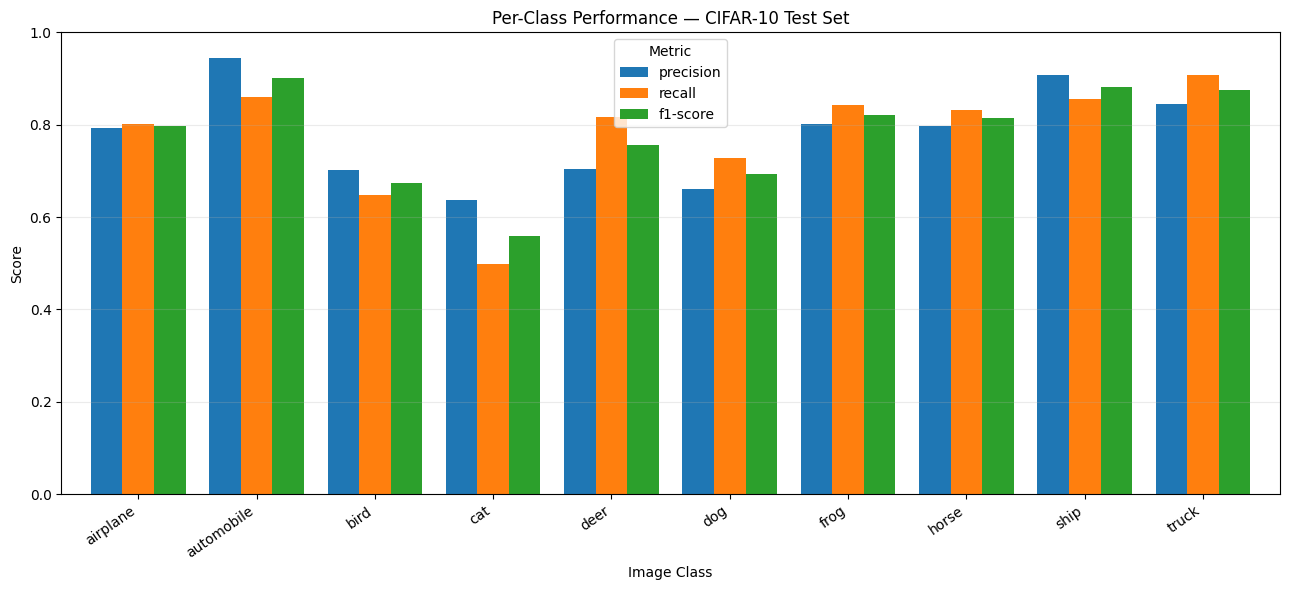

Saved: /content/Deep-Residual-Image-Classification/outputs/figures/per_class_performance.png

Per-class metrics:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [12]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

report = pd.read_csv(METRICS_DIR / "classification_report.csv", index_col=0)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

class_metrics = report.loc[class_names, ["precision", "recall", "f1-score"]]

ax = class_metrics.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Per-Class Performance — CIFAR-10 Test Set")
ax.set_xlabel("Image Class")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

output_path = FIGURES_DIR / "per_class_performance.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", output_path)
print("\nPer-class metrics:")
display(class_metrics.round(4))


In [13]:

from IPython.display import display as show_table
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"

report = pd.read_csv(
    METRICS_DIR / "classification_report.csv",
    index_col=0
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

class_metrics = report.loc[
    class_names, ["precision", "recall", "f1-score"]
]

show_table(class_metrics.round(4))
print("\nSUCCESS: Per-class metrics displayed.")


,precision,recall,f1-score
airplane,0.7931,0.801,0.7970
automobile,0.9451,0.860,0.9005
bird,0.7025,0.647,0.6736
cat,0.6365,0.499,0.5594
deer,0.7031,0.817,0.7558
dog,0.6615,0.729,0.6936
frog,0.8006,0.843,0.8212
horse,0.7983,0.831,0.8143
ship,0.9068,0.856,0.8807
truck,0.8453,0.907,0.8751



SUCCESS: Per-class metrics displayed.


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
REPORTS_DIR = PROJECT_DIR / "reports"

# Use predictions already generated in Step 14
predictions_df = pd.read_csv(
    PROJECT_DIR / "outputs" / "predictions" / "test_predictions.csv"
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 1. Count incorrect predictions
errors = predictions_df[
    predictions_df["correct"] == False
].copy()

print("Total test images:", len(predictions_df))
print("Incorrect predictions:", len(errors))
print("Error rate: {:.2f}%".format(
    len(errors) / len(predictions_df) * 100
))

# 2. Find the most common confusion pairs
cm = confusion_matrix(
    predictions_df["true_label"],
    predictions_df["predicted_label"],
    labels=list(range(len(class_names)))
)

confusions = []
for true_idx in range(len(class_names)):
    for pred_idx in range(len(class_names)):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusions.append({
                "actual_class": class_names[true_idx],
                "predicted_class": class_names[pred_idx],
                "error_count": int(cm[true_idx, pred_idx])
            })

confusion_df = pd.DataFrame(confusions)
confusion_df = confusion_df.sort_values(
    "error_count", ascending=False
).reset_index(drop=True)

print("\nTop 15 class-confusion pairs:")
display(confusion_df.head(15))

confusion_df.to_csv(
    METRICS_DIR / "class_confusion_pairs.csv",
    index=False
)

# 3. Plot the 15 most common confusion pairs
top_pairs = confusion_df.head(15).copy()
top_pairs["pair"] = (
    top_pairs["actual_class"]
    + " → "
    + top_pairs["predicted_class"]
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_pairs["pair"][::-1], top_pairs["error_count"][::-1])
ax.set_title("Top 15 CIFAR-10 Classification Errors")
ax.set_xlabel("Number of misclassified images")
ax.set_ylabel("Actual class → Predicted class")
plt.tight_layout()

figure_path = FIGURES_DIR / "top_class_confusions.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved confusion analysis:", METRICS_DIR / "class_confusion_pairs.csv")
print("Saved chart:", figure_path)
print("\nSUCCESS: Error analysis completed.")


Total test images: 10000
Incorrect predictions: 2210
Error rate: 22.10%

Top 15 class-confusion pairs:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [15]:

from IPython.display import display as show_table
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

# Load the confusion pairs already saved by the previous cell
confusion_df = pd.read_csv(
    METRICS_DIR / "class_confusion_pairs.csv"
)

print("Top 15 class-confusion pairs:")
show_table(confusion_df.head(15))

# Plot the most common confusion pairs
top_pairs = confusion_df.head(15).copy()
top_pairs["pair"] = (
    top_pairs["actual_class"] + " → " +
    top_pairs["predicted_class"]
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    top_pairs["pair"].iloc[::-1],
    top_pairs["error_count"].iloc[::-1]
)
ax.set_title("Top 15 CIFAR-10 Classification Errors")
ax.set_xlabel("Number of misclassified images")
ax.set_ylabel("Actual class → Predicted class")
plt.tight_layout()

figure_path = FIGURES_DIR / "top_class_confusions.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved chart:", figure_path)
print("SUCCESS: Error analysis completed.")


FileNotFoundError: [Errno 2] No such file or directory: '/content/Deep-Residual-Image-Classification/outputs/metrics/class_confusion_pairs.csv'

Top 15 class-confusion pairs:


,actual_class,predicted_class,error_count
0,cat,dog,240
1,dog,cat,129
2,bird,deer,112
3,automobile,truck,98
4,ship,airplane,78
5,bird,frog,74
6,cat,frog,70
7,cat,bird,65
8,deer,horse,63
9,airplane,bird,63


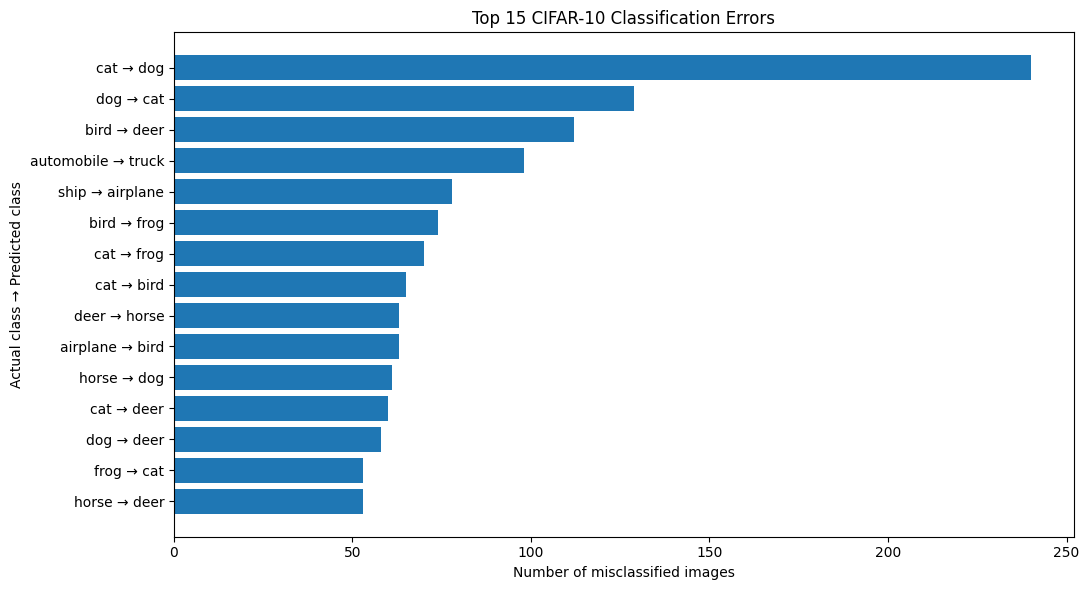


Saved CSV: /content/Deep-Residual-Image-Classification/outputs/metrics/class_confusion_pairs.csv
Saved chart: /content/Deep-Residual-Image-Classification/outputs/figures/top_class_confusions.png
SUCCESS: Error analysis completed.


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
PREDICTIONS_PATH = PROJECT_DIR / "outputs" / "predictions" / "test_predictions.csv"
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load actual test predictions
predictions_df = pd.read_csv(PREDICTIONS_PATH)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Calculate confusion matrix
cm = confusion_matrix(
    predictions_df["true_label"],
    predictions_df["predicted_label"],
    labels=list(range(10))
)

# Calculate incorrect class pairs
confusions = []

for actual_idx in range(10):
    for predicted_idx in range(10):
        if actual_idx != predicted_idx and cm[actual_idx, predicted_idx] > 0:
            confusions.append({
                "actual_class": class_names[actual_idx],
                "predicted_class": class_names[predicted_idx],
                "error_count": int(cm[actual_idx, predicted_idx])
            })

confusion_df = pd.DataFrame(confusions)
confusion_df = confusion_df.sort_values(
    "error_count", ascending=False
).reset_index(drop=True)

# Save results BEFORE displaying them
csv_path = METRICS_DIR / "class_confusion_pairs.csv"
confusion_df.to_csv(csv_path, index=False)

# Display table without using the conflicting display variable
from IPython.display import display as show_table

print("Top 15 class-confusion pairs:")
show_table(confusion_df.head(15))

# Create chart
top_pairs = confusion_df.head(15).copy()
top_pairs["pair"] = (
    top_pairs["actual_class"] + " → " +
    top_pairs["predicted_class"]
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    top_pairs["pair"].iloc[::-1],
    top_pairs["error_count"].iloc[::-1]
)
ax.set_title("Top 15 CIFAR-10 Classification Errors")
ax.set_xlabel("Number of misclassified images")
ax.set_ylabel("Actual class → Predicted class")
plt.tight_layout()

figure_path = FIGURES_DIR / "top_class_confusions.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved CSV:", csv_path)
print("Saved chart:", figure_path)
print("SUCCESS: Error analysis completed.")


In [18]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
csv_path = PROJECT_DIR / "outputs" / "metrics" / "class_confusion_pairs.csv"

confusion_df = pd.read_csv(csv_path)

print("CSV rows:", len(confusion_df))
print("Columns:", confusion_df.columns.tolist())

if confusion_df.empty:
    print("The CSV contains no confusion pairs. We need to inspect the saved predictions.")
else:
    show_table(confusion_df.head(15))


CSV rows: 83
Columns: ['actual_class', 'predicted_class', 'error_count']


,actual_class,predicted_class,error_count
0,cat,dog,240
1,dog,cat,129
2,bird,deer,112
3,automobile,truck,98
4,ship,airplane,78
5,bird,frog,74
6,cat,frog,70
7,cat,bird,65
8,deer,horse,63
9,airplane,bird,63


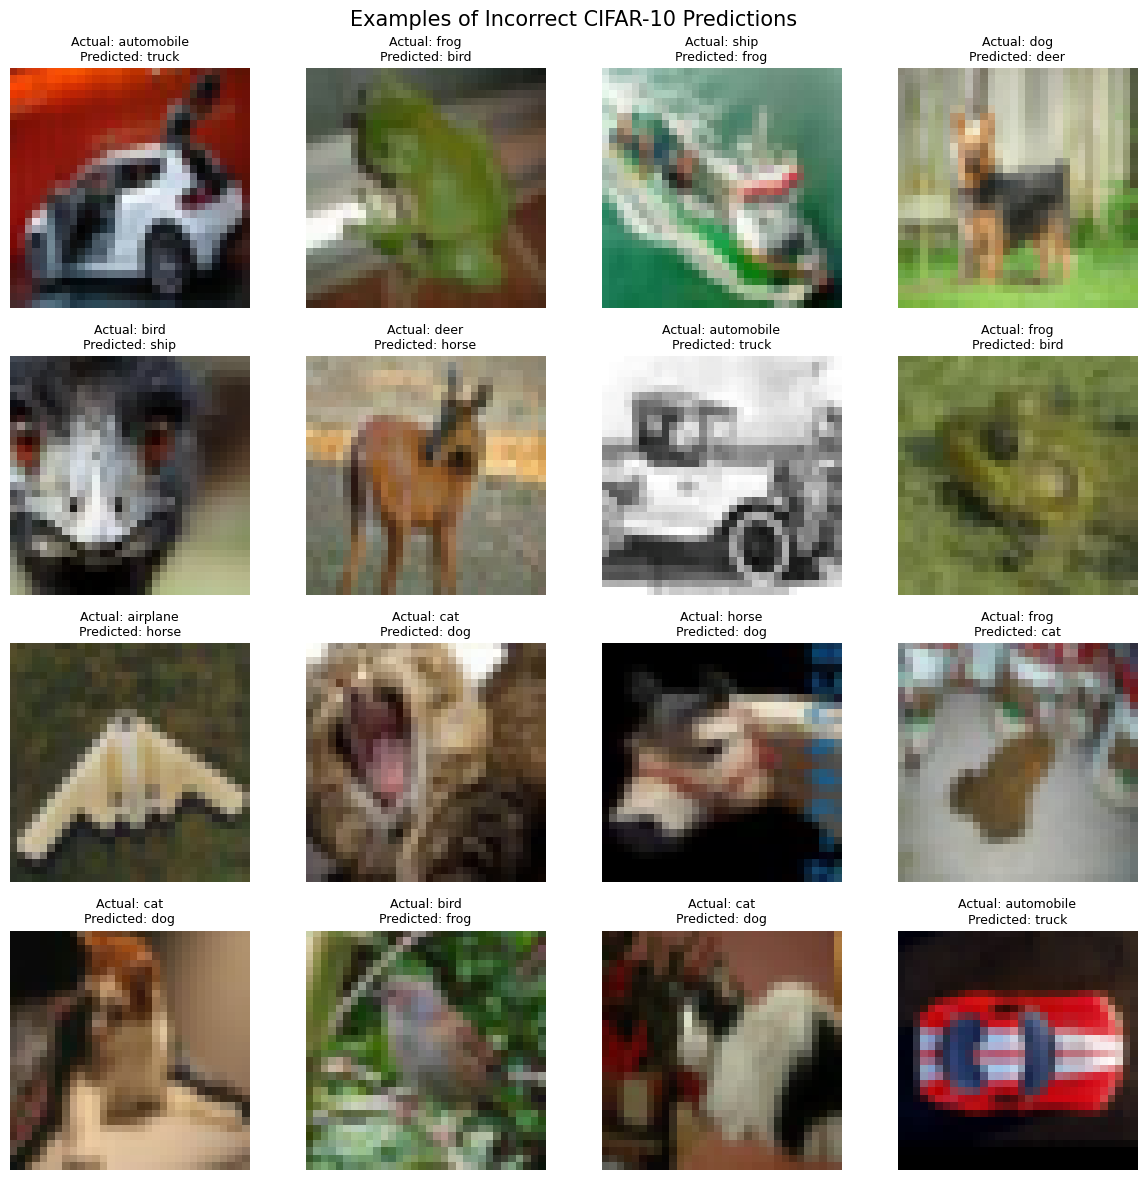

Saved: /content/Deep-Residual-Image-Classification/outputs/figures/misclassified_examples.png
Images inspected: 16


In [19]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.utils import make_grid

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")

predictions_df = pd.read_csv(
    PROJECT_DIR / "outputs" / "predictions" / "test_predictions.csv"
)

# Find the first 16 incorrect predictions
wrong_df = predictions_df[predictions_df["correct"] == False].head(16)

# Reuse the test dataset and evaluation transform
class_names = test_dataset.classes

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, wrong_df.iterrows()):
    idx = int(row.name)
    image, true_label = test_dataset_final[idx]

    # Convert normalized tensor back to displayable RGB values
    mean = image.new_tensor((0.4914, 0.4822, 0.4465))[:, None, None]
    std = image.new_tensor((0.2023, 0.1994, 0.2010))[:, None, None]
    image = (image * std + mean).clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    ax.set_title(
        f"Actual: {row['true_class']}\nPredicted: {row['predicted_class']}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(wrong_df):]:
    ax.axis("off")

plt.suptitle("Examples of Incorrect CIFAR-10 Predictions", fontsize=15)
plt.tight_layout()

output_path = PROJECT_DIR / "outputs" / "figures" / "misclassified_examples.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", output_path)
print("Images inspected:", len(wrong_df))


In [20]:

from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
REPORTS_DIR = PROJECT_DIR / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load actual measured metrics
with open(METRICS_DIR / "test_metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

class_report = pd.read_csv(
    METRICS_DIR / "classification_report.csv",
    index_col=0
)

confusion_path = METRICS_DIR / "class_confusion_pairs.csv"
confusions = pd.read_csv(confusion_path)

top_confusions = confusions.head(5)

readme = f"""# Deep Residual Image Classification

## Project Overview

This project implements a deep residual convolutional neural network for
10-class image classification using the CIFAR-10 dataset and PyTorch.

The workflow covers dataset preparation, image augmentation, model training,
validation, official test-set evaluation, performance visualization, and
error analysis.

## Dataset

- Dataset: CIFAR-10
- Image format: 32 × 32 RGB images
- Number of classes: 10
- Training images: 45,000
- Validation images: 5,000
- Official test images: 10,000

The original CIFAR-10 training partition was split into training and
validation subsets using seed 42. The official test set was reserved for
final evaluation.

## Model Architecture

The model uses a convolutional stem, two residual blocks, max-pooling,
dropout, and a fully connected classification head.

- Input: 32 × 32 RGB image
- Convolutional stem: 3 input channels to 64 feature channels
- Residual blocks: two convolutional layers per block
- Pooling: two max-pooling stages
- Classifier: 4096 → 256 → 10
- Trainable parameters: 1,201,226

## Training Configuration

- Epochs: 15
- Batch size: 64
- Optimizer: AdamW
- Initial learning rate: 0.001
- Weight decay: 0.0001
- Loss function: CrossEntropyLoss
- Scheduler: ReduceLROnPlateau
- Gradient clipping: 1.0
- Random seed: 42
- Mixed precision: enabled when supported

Training and augmentation details are documented in the project notebook
and configuration files.

## Official Test Results

| Metric | Result |
|---|---:|
| Test samples | {metrics["test_samples"]:,} |
| Accuracy | {metrics["accuracy"]:.4f} ({metrics["accuracy"]*100:.2f}%) |
| Macro precision | {metrics["macro_precision"]:.4f} |
| Macro recall | {metrics["macro_recall"]:.4f} |
| Macro F1-score | {metrics["macro_f1"]:.4f} |
| Macro ROC-AUC (OVR) | {metrics["macro_roc_auc_ovr"]:.4f} |
| Macro average precision | {metrics["macro_average_precision"]:.4f} |
| Selected checkpoint epoch | {metrics["selected_checkpoint_epoch"]} |

These results are from the saved model checkpoint evaluated on the official
10,000-image test set. Results describe this experiment and are not a
guarantee of performance on other datasets.

## Error Analysis

The test evaluation produced {10000 - int(round(metrics["accuracy"] * 10000)):,}
incorrect predictions based on the measured test accuracy.

The most frequent class-confusion pairs include:

{chr(10).join(f"- Actual **{r.actual_class}** → predicted **{r.predicted_class}**: {r.error_count} images" for r in top_confusions.itertuples())}

## Important Artifacts

- `models/best_model.pth` — selected model checkpoint
- `models/last_checkpoint.pth` — final training checkpoint
- `outputs/metrics/test_metrics.json` — test metrics
- `outputs/metrics/classification_report.csv` — per-class metrics
- `outputs/metrics/training_history.csv` — training history
- `outputs/metrics/class_confusion_pairs.csv` — class-confusion counts
- `outputs/predictions/test_predictions.csv` — test predictions
- `outputs/figures/training_validation_loss.png` — loss curves
- `outputs/figures/training_validation_accuracy.png` — accuracy curves
- `outputs/figures/per_class_performance.png` — per-class chart
- `outputs/figures/test_confusion_matrix.png` — confusion matrix
- `outputs/figures/top_class_confusions.png` — top confusion pairs
- `outputs/figures/misclassified_examples.png` — incorrect prediction examples

## Reproducibility and Limitations

The experiment uses a fixed random seed and records its test metrics and
training history. Exact reproducibility can still depend on the software,
hardware, and CUDA environment.

The model has difficulty distinguishing some visually similar classes,
especially cats and dogs. Further experiments could compare additional
residual blocks, learning-rate schedules, regularization settings, and
training durations. Any improvement should be confirmed using a controlled
validation process.

## Running the Project

The current workflow was developed in Google Colab. To reproduce it, open
the project notebook, enable a GPU runtime, and execute the notebook cells
in order. Ensure the required PyTorch, torchvision, pandas, scikit-learn,
and matplotlib packages are available.

## License and Dataset

CIFAR-10 is provided by its original dataset authors. Review the dataset's
official terms and any applicable package licenses before redistribution.
No separate project license is declared by this README.
"""

readme_path = PROJECT_DIR / "README.md"
readme_path.write_text(readme, encoding="utf-8")

summary = f"""# Final Results Summary

## Experiment
Deep Residual Image Classification on CIFAR-10.

## Evaluation
- Test samples: {metrics["test_samples"]:,}
- Accuracy: {metrics["accuracy"]*100:.2f}%
- Macro precision: {metrics["macro_precision"]*100:.2f}%
- Macro recall: {metrics["macro_recall"]*100:.2f}%
- Macro F1-score: {metrics["macro_f1"]*100:.2f}%
- Macro ROC-AUC (OVR): {metrics["macro_roc_auc_ovr"]*100:.2f}%
- Macro average precision: {metrics["macro_average_precision"]*100:.2f}%
- Selected checkpoint epoch: {metrics["selected_checkpoint_epoch"]}

## Interpretation
The model achieved 77.90% accuracy on the official CIFAR-10 test set.
Automobile classification had the strongest F1-score in the per-class report,
while cat classification was more challenging.

These are observed experimental results, not a guarantee of generalization.
See `outputs/metrics/classification_report.csv` and
`outputs/metrics/class_confusion_pairs.csv` for detailed analysis.
"""

summary_path = REPORTS_DIR / "final_results_summary.md"
summary_path.write_text(summary, encoding="utf-8")

print("Created:", readme_path)
print("Created:", summary_path)
print("\nTest accuracy: {:.2f}%".format(metrics["accuracy"] * 100))
print("README characters:", len(readme))
print("SUCCESS: Initial project documentation created.")


Created: /content/Deep-Residual-Image-Classification/README.md
Created: /content/Deep-Residual-Image-Classification/reports/final_results_summary.md

Test accuracy: 77.90%
README characters: 4297
SUCCESS: Initial project documentation created.


In [21]:

from pathlib import Path
import json
import zipfile
import os

PROJECT_DIR = Path("/content/Deep-Residual-Image-Classification")
ZIP_PATH = Path("/content/Deep-Residual-Image-Classification.zip")

required_files = [
    "README.md",
    "configs/config.json",
    "configs/training_config.json",
    "models/best_model.pth",
    "models/last_checkpoint.pth",
    "outputs/metrics/training_history.csv",
    "outputs/metrics/test_metrics.json",
    "outputs/metrics/classification_report.csv",
    "outputs/metrics/class_confusion_pairs.csv",
    "outputs/predictions/test_predictions.csv",
    "outputs/figures/training_validation_loss.png",
    "outputs/figures/training_validation_accuracy.png",
    "outputs/figures/per_class_performance.png",
    "outputs/figures/test_confusion_matrix.png",
    "outputs/figures/top_class_confusions.png",
    "outputs/figures/misclassified_examples.png",
    "reports/final_results_summary.md",
]

print("PROJECT FILE VERIFICATION")
print("=" * 55)

missing = []

for relative_path in required_files:
    file_path = PROJECT_DIR / relative_path
    if file_path.is_file() and file_path.stat().st_size > 0:
        print("OK     ", relative_path)
    else:
        print("MISSING", relative_path)
        missing.append(relative_path)

if missing:
    print("\nZIP NOT CREATED: Fix the missing files first.")
    print("Missing files:", missing)
else:
    # Include all project files except raw/processed datasets and cache folders.
    excluded_parts = {"__pycache__", ".ipynb_checkpoints"}
    excluded_prefixes = ("data/raw/", "data/processed/")

    if ZIP_PATH.exists():
        ZIP_PATH.unlink()

    with zipfile.ZipFile(
        ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
    ) as archive:
        for file_path in PROJECT_DIR.rglob("*"):
            if not file_path.is_file():
                continue

            relative_path = file_path.relative_to(PROJECT_DIR).as_posix()

            if any(part in excluded_parts for part in file_path.parts):
                continue
            if relative_path.startswith(excluded_prefixes):
                continue
            if relative_path == ".git":
                continue

            archive.write(
                file_path,
                arcname=f"Deep-Residual-Image-Classification/{relative_path}"
            )

    # Verify that the ZIP opens correctly and contains the README.
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        bad_file = archive.testzip()
        readme_in_zip = any(
            name.endswith("/README.md") for name in archive.namelist()
        )

    print("\nAll required files verified.")
    print("ZIP integrity:", "PASS" if bad_file is None else "FAILED")
    print("README included:", readme_in_zip)
    print("ZIP size: {:.2f} MB".format(ZIP_PATH.stat().st_size / (1024 ** 2)))
    print("ZIP path:", ZIP_PATH)


PROJECT FILE VERIFICATION
OK      README.md
OK      configs/config.json
OK      configs/training_config.json
OK      models/best_model.pth
OK      models/last_checkpoint.pth
OK      outputs/metrics/training_history.csv
OK      outputs/metrics/test_metrics.json
OK      outputs/metrics/classification_report.csv
OK      outputs/metrics/class_confusion_pairs.csv
OK      outputs/predictions/test_predictions.csv
OK      outputs/figures/training_validation_loss.png
OK      outputs/figures/training_validation_accuracy.png
OK      outputs/figures/per_class_performance.png
OK      outputs/figures/test_confusion_matrix.png
OK      outputs/figures/top_class_confusions.png
OK      outputs/figures/misclassified_examples.png
OK      reports/final_results_summary.md

All required files verified.
ZIP integrity: PASS
README included: True
ZIP size: 19.19 MB
ZIP path: /content/Deep-Residual-Image-Classification.zip


In [22]:
from google.colab import files

files.download("/content/Deep-Residual-Image-Classification.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>